# Week 03 · Student Markov Chain and MRP — 학생 마르코프 체인과 마르코프 보상 과정

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week03_markov_decision_process/01_student_mrp.ipynb)

슬라이드 *"Example: Student Markov Chain"* (Episodes, Transition Matrix), *"Example: Student MRP"*,
*"Example: Student MRP Returns"* (— Worked Out), *"Example: State-Value Function for Student MRP (1)–(3)"*,
*"Example: Bellman Equation for Student MRP"*, *"Bellman Equation: Checking Every State"*,
*"Why the Values Cannot Be Read Off One at a Time"*, *"Bellman Equation in Matrix Form"*, *"Solving the Bellman Equation"* 을 재현합니다.
에피소드를 직접 샘플링하고, 반환값과 가치 함수를 계산해 슬라이드의 모든 숫자와 비교합니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이 노트북에서 추가로 쓰는 것
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch

## 1. 학생 마르코프 체인 (Example: Student Markov Chain)

마르코프 과정(Markov process)은 $\langle \mathcal{S}, \mathcal{P} \rangle$ 입니다. 상태는 7개
(C1, C2, C3 = 수업 1–3, Pass, Pub, YT = Youtube, Sleep)이고, Sleep은 한 번 들어가면 나오지 않는 종료 상태입니다.
상태 순서는 슬라이드의 전이 행렬과 같게 C1, C2, C3, Pass, Pub, YT, Sleep으로 둡니다.

In [2]:
STATES = ["C1", "C2", "C3", "Pass", "Pub", "YT", "Sleep"]
S = {s: i for i, s in enumerate(STATES)}          # name -> index

# (from, to, probability) — 슬라이드 그림의 화살표
TRANSITIONS = [
    ("C1", "C2", 0.5), ("C1", "YT", 0.5),
    ("C2", "C3", 0.8), ("C2", "Sleep", 0.2),
    ("C3", "Pass", 0.6), ("C3", "Pub", 0.4),
    ("Pass", "Sleep", 1.0),
    ("Pub", "C1", 0.2), ("Pub", "C2", 0.4), ("Pub", "C3", 0.4),
    ("YT", "C1", 0.1), ("YT", "YT", 0.9),
    ("Sleep", "Sleep", 1.0),                        # 종료 상태: 자기 자신으로 (흡수 상태)
]
P = np.zeros((7, 7))
for s, s2, p in TRANSITIONS:
    P[S[s], S[s2]] = p
assert np.allclose(P.sum(axis=1), 1.0)             # 각 행의 합은 1
print(P)

[[0.  0.5 0.  0.  0.  0.5 0. ]
 [0.  0.  0.8 0.  0.  0.  0.2]
 [0.  0.  0.  0.6 0.4 0.  0. ]
 [0.  0.  0.  0.  0.  0.  1. ]
 [0.2 0.4 0.4 0.  0.  0.  0. ]
 [0.1 0.  0.  0.  0.  0.9 0. ]
 [0.  0.  0.  0.  0.  0.  1. ]]


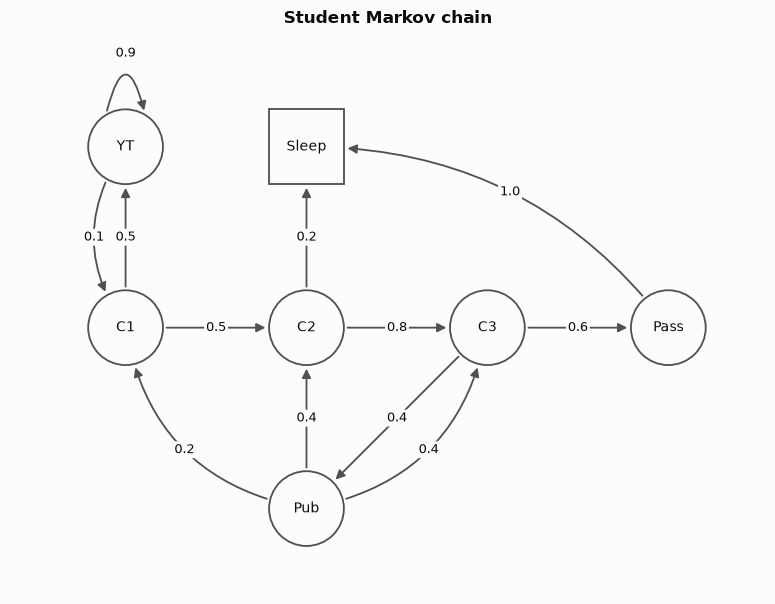

In [3]:
POS = {"C1": (0, 0), "C2": (3, 0), "C3": (6, 0), "Pass": (9, 0), "Sleep": (3, 3), "YT": (0, 3), "Pub": (3, -3)}
NODE_R = 0.62
# 곡선으로 그릴 화살표의 휘어짐 (나머지는 직선)
CURVE = {("YT", "C1"): 0.35, ("Pass", "Sleep"): 0.25, ("Pub", "C1"): -0.35, ("Pub", "C3"): 0.35}


def text_color_on(face_rgba):
    """Black text on light nodes, white text on dark nodes."""
    r, g, b = face_rgba[:3]
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "#0b0b0b"


def draw_chain(ax, values=None, norm=None, rewards=None, edge_labels=True, highlight=(), title=None, value_fmt="{:.1f}"):
    """Draw the Student Markov chain / MRP.
    values: array over STATES shown inside the nodes (colored with DIV_CMAP), rewards: array shown next to nodes,
    highlight: states whose outgoing arrows are drawn in orange."""
    patches = {}
    for s, (x, y) in POS.items():
        face = mpl.colors.to_rgba("#fcfcfb") if values is None else DIV_CMAP(norm(values[S[s]]))
        if s == "Sleep":
            patch = Rectangle((x - NODE_R, y - NODE_R), 2 * NODE_R, 2 * NODE_R, fc=face, ec="#52514e", lw=1.2, zorder=3)
        else:
            patch = Circle((x, y), NODE_R, fc=face, ec=PALETTE[1] if s in highlight else "#52514e",
                           lw=2.2 if s in highlight else 1.2, zorder=3)
        ax.add_patch(patch)
        patches[s] = patch
        tc = text_color_on(face)
        if values is None:
            ax.text(x, y, s, ha="center", va="center", fontsize=9, zorder=4)
        else:
            ax.text(x, y + 0.26, s, ha="center", va="center", fontsize=7.5, color=tc, zorder=4)
            ax.text(x, y - 0.13, value_fmt.format(values[S[s]]), ha="center", va="center", fontsize=10.5,
                    fontweight="bold", color=tc, zorder=4)
        if rewards is not None:
            r = rewards[S[s]]
            ax.text(x + 0.5, y - 0.8, "R=0" if r == 0 else f"R={r:+g}", fontsize=8, color=PALETTE[7], zorder=4)

    for s, s2, p in TRANSITIONS:
        if s == "Sleep":
            continue
        color, lw = (PALETTE[1], 2.2) if s in highlight else ("#52514e", 1.2)
        x1, y1 = POS[s]
        x2, y2 = POS[s2]
        if s == s2:        # self-loop above the node
            arrow = FancyArrowPatch((x1 - 0.32, y1 + 0.55), (x1 + 0.32, y1 + 0.55), connectionstyle="arc3,rad=-2.0",
                                    arrowstyle="-|>", mutation_scale=12, color=color, lw=lw, zorder=2)
            lx, ly = x1, y1 + 1.55
        else:
            rad = CURVE.get((s, s2), 0.0)
            arrow = FancyArrowPatch((x1, y1), (x2, y2), patchA=patches[s], patchB=patches[s2],
                                    connectionstyle=f"arc3,rad={rad}", arrowstyle="-|>", mutation_scale=12,
                                    color=color, lw=lw, zorder=2)
            dx, dy = x2 - x1, y2 - y1
            lx, ly = (x1 + x2) / 2 + 0.5 * rad * dy, (y1 + y2) / 2 - 0.5 * rad * dx
        ax.add_patch(arrow)
        if edge_labels:
            ax.text(lx, ly, f"{p:.1f}", ha="center", va="center", fontsize=8.5, zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="#fcfcfb", ec="none"))
    ax.set_xlim(-1.9, 10.6)
    ax.set_ylim(-4.4, 4.9)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title)


fig, ax = plt.subplots(figsize=(7.5, 5.6))
draw_chain(ax, title="Student Markov chain")
plt.tight_layout()
plt.show()

## 2. 전이 행렬 (Example: Student Markov Chain Transition Matrix)

$\mathcal{P}_{ss'} = \Pr[S_{t+1}=s' \mid S_t = s]$, 행 = 현재 상태(from), 열 = 다음 상태(to).

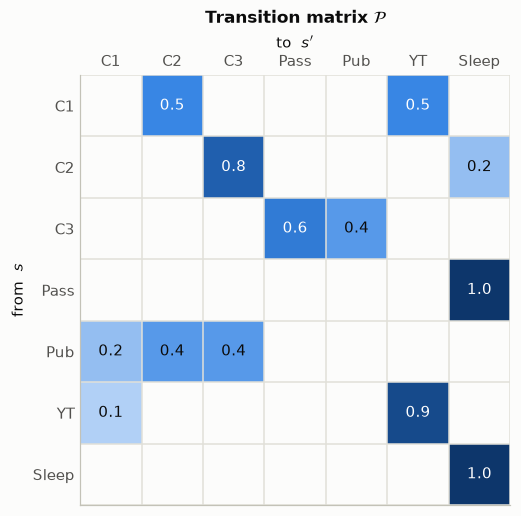

transition matrix matches the slide


In [4]:
fig, ax = plt.subplots(figsize=(5.6, 4.8))
cmap = SEQ_CMAP.with_extremes(bad="#fcfcfb")
ax.imshow(np.ma.masked_equal(P, 0), cmap=cmap, vmin=0, vmax=1)
for i in range(7):
    for j in range(7):
        if P[i, j] > 0:
            ax.text(j, i, f"{P[i, j]:.1f}", ha="center", va="center", fontsize=10, color=text_color_on(cmap(P[i, j])))
ax.set_xticks(range(7), STATES)
ax.set_yticks(range(7), STATES)
ax.xaxis.tick_top()
ax.set_xlabel("to  $s'$")
ax.xaxis.set_label_position("top")
ax.set_ylabel("from  $s$")
ax.set_xticks(np.arange(-0.5, 7, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 7, 1), minor=True)
ax.grid(False)
ax.grid(which="minor", color="#e1e0d9", lw=1)
ax.tick_params(which="both", length=0)
ax.set_title("Transition matrix $\\mathcal{P}$", pad=34)
plt.tight_layout()
plt.show()

# 슬라이드와 비교: 슬라이드 행렬의 0이 아닌 칸 (행 순서 C1, C2, C3, Pass, Pub, YT, Sleep)
SLIDE_P = np.array([
    [0,   0.5, 0,   0,   0,   0.5, 0  ],
    [0,   0,   0.8, 0,   0,   0,   0.2],
    [0,   0,   0,   0.6, 0.4, 0,   0  ],
    [0,   0,   0,   0,   0,   0,   1.0],
    [0.2, 0.4, 0.4, 0,   0,   0,   0  ],
    [0.1, 0,   0,   0,   0,   0.9, 0  ],
    [0,   0,   0,   0,   0,   0,   1.0],
])
assert np.array_equal(P, SLIDE_P)
print("transition matrix matches the slide")

## 3. 에피소드 샘플링 (Example: Student Markov Chain Episodes)

C1에서 출발해 Sleep에 도달할 때까지 $\mathcal{P}$에 따라 다음 상태를 뽑습니다. 슬라이드의 네 에피소드가 이 체인에서 실제로
가능한 경로인지, 그리고 각각의 확률(전이 확률의 곱)이 얼마인지도 계산합니다.

In [5]:
def sample_episode(start, rng):
    """Sample S_1, S_2, ..., S_T from the chain until Sleep."""
    episode = [start]
    while episode[-1] != "Sleep":
        episode.append(STATES[rng.choice(7, p=P[S[episode[-1]]])])
    return episode


def episode_probability(episode):
    """Product of the transition probabilities along the episode."""
    return np.prod([P[S[a], S[b]] for a, b in zip(episode[:-1], episode[1:])])


print("sampled episodes from C1:")
for _ in range(4):
    print("  ", " ".join(sample_episode("C1", rng)))

SLIDE_EPISODES = [
    "C1 C2 C3 Pass Sleep",
    "C1 YT YT C1 C2 Sleep",
    "C1 C2 C3 Pub C2 C3 Pass Sleep",
    "C1 YT YT C1 C2 C3 Pub C1 YT YT YT C1 C2 C3 Pub C2 Sleep",
]
print("\nslide episodes and their probabilities:")
for ep in SLIDE_EPISODES:
    prob = episode_probability(ep.split())
    assert prob > 0                                   # every slide episode is a valid path
    print(f"  {prob:10.2e}   {ep}")

sampled episodes from C1:
   C1 YT YT C1 C2 Sleep
   C1 YT YT YT YT YT YT C1 YT C1 YT YT YT YT YT YT C1 C2 C3 Pub C3 Pass Sleep
   C1 YT YT YT YT YT YT YT YT YT YT YT YT YT YT YT YT YT YT YT YT YT C1 YT YT YT YT C1 C2 C3 Pass Sleep
   C1 C2 C3 Pass Sleep

slide episodes and their probabilities:
    2.40e-01   C1 C2 C3 Pass Sleep
    4.50e-03   C1 YT YT C1 C2 Sleep
    3.07e-02   C1 C2 C3 Pub C2 C3 Pass Sleep
    7.46e-07   C1 YT YT C1 C2 C3 Pub C1 YT YT YT C1 C2 C3 Pub C2 Sleep


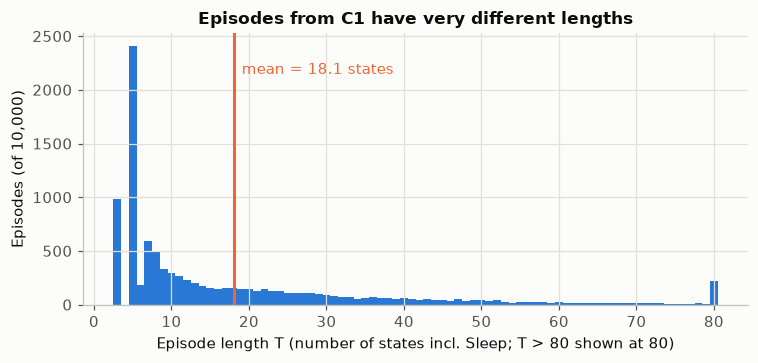

In [6]:
lengths = np.array([len(sample_episode("C1", rng)) for _ in range(10_000)])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(np.minimum(lengths, 80), bins=np.arange(2.5, 81.5, 1), color=PALETTE[0])   # 80 이상은 마지막 칸에
ax.axvline(lengths.mean(), color=PALETTE[1], lw=2)
ax.text(lengths.mean() + 1, ax.get_ylim()[1] * 0.85, f"mean = {lengths.mean():.1f} states", color=PALETTE[1])
ax.set_xlabel("Episode length T (number of states incl. Sleep; T > 80 shown at 80)")
ax.set_ylabel("Episodes (of 10,000)")
ax.set_title("Episodes from C1 have very different lengths")
plt.tight_layout()
plt.show()

가장 짧은 에피소드 C1 C2 Sleep (길이 3)부터, YT에 오래 머무르는 긴 에피소드까지 길이가 크게 다릅니다.
슬라이드의 네 에피소드는 모두 확률이 0보다 큰, 실제로 일어날 수 있는 경로입니다.

## 4. 학생 MRP (Example: Student MRP)

마르코프 보상 과정(Markov reward process, MRP)은 $\langle \mathcal{S}, \mathcal{P}, \mathcal{R}, \gamma \rangle$입니다.
상태를 떠날 때 받는 보상 $\mathcal{R}_s = \mathbb{E}[R_{t+1} \mid S_t = s]$는 슬라이드 그림과 같습니다.

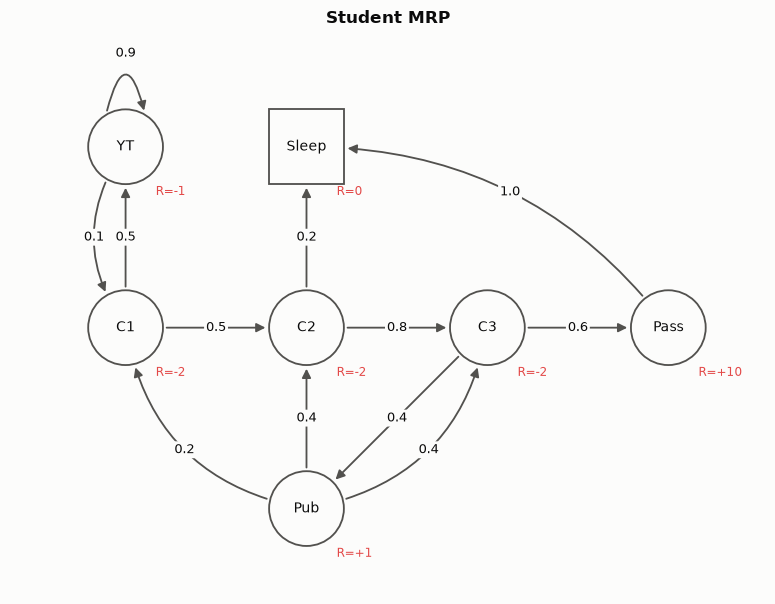

In [7]:
R = np.array([-2.0, -2.0, -2.0, 10.0, 1.0, -1.0, 0.0])   # C1, C2, C3, Pass, Pub, YT, Sleep

fig, ax = plt.subplots(figsize=(7.5, 5.6))
draw_chain(ax, rewards=R, title="Student MRP")
plt.tight_layout()
plt.show()

## 5. 반환값 (Example: Student MRP Returns / — Worked Out)

$\gamma = \tfrac12$일 때 C1에서 시작한 에피소드의 반환값
$G_1 = R_2 + \tfrac12 R_3 + \tfrac14 R_4 + \cdots$ 를 계산합니다. $R_{k+1}$은 $k$번째 상태를 떠날 때 받는 보상이므로
$G_1 = \sum_k \gamma^{k-1}\mathcal{R}_{S_k}$ 입니다.

In [8]:
def episode_return(episode, gamma):
    """G_1 = sum_k gamma^(k-1) * R(S_k) for an episode given as a list of state names."""
    return sum(gamma**k * R[S[s]] for k, s in enumerate(episode))


SLIDE_RETURNS = [-2.25, -3.125, -3.41, -3.20]
print(f"{'episode':60} {'slide':>7} {'computed':>9}")
for ep, g_slide in zip(SLIDE_EPISODES, SLIDE_RETURNS):
    g = episode_return(ep.split(), 0.5)
    print(f"{ep:60} {g_slide:7.3f} {g:9.4f}")
    assert abs(g - g_slide) < 0.005                    # slide rounds to 2-3 decimals

episode                                                        slide  computed
C1 C2 C3 Pass Sleep                                           -2.250   -2.2500
C1 YT YT C1 C2 Sleep                                          -3.125   -3.1250
C1 C2 C3 Pub C2 C3 Pass Sleep                                 -3.410   -3.4062
C1 YT YT C1 C2 C3 Pub C1 YT YT YT C1 C2 C3 Pub C2 Sleep       -3.200   -3.1960


네 값 모두 슬라이드와 같습니다. 이제 표의 마지막 줄(*"— Worked Out"*): YT YT YT C1 C2 C3 Pub C2 Sleep.

step k :        1         2         3         4         5         6         7         8         9
state  :       YT        YT        YT        C1        C2        C3       Pub        C2     Sleep
reward :       -1        -1        -1        -2        -2        -2         1        -2         0
weight :  1.00000   0.50000   0.25000   0.12500   0.06250   0.03125   0.01562   0.00781   0.00391
term   : -1.00000  -0.50000  -0.25000  -0.25000  -0.12500  -0.06250   0.01562  -0.01562   0.00000

G_1 = -2.1875   (slide: -2.1875)


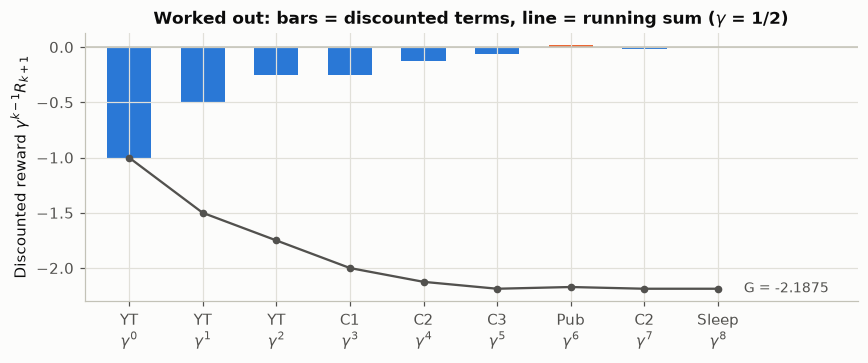

In [9]:
worked = "YT YT YT C1 C2 C3 Pub C2 Sleep".split()
gamma = 0.5
rewards = np.array([R[S[s]] for s in worked])
weights = gamma ** np.arange(len(worked))
terms = weights * rewards
print("step k :", "  ".join(f"{k + 1:>8d}" for k in range(len(worked))))
print("state  :", "  ".join(f"{s:>8}" for s in worked))
print("reward :", "  ".join(f"{r:>8.0f}" for r in rewards))
print("weight :", "  ".join(f"{w:>8.5f}" for w in weights))
print("term   :", "  ".join(f"{t:>8.5f}" for t in terms))
G_worked = terms.sum()
print(f"\nG_1 = {G_worked}   (slide: -2.1875)")
assert G_worked == -2.1875

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(worked))
ax.bar(x, terms, color=[PALETTE[0] if t < 0 else PALETTE[1] for t in terms], width=0.6)
ax.plot(x, np.cumsum(terms), color="#52514e", marker="o", lw=1.5, ms=4)
ax.text(x[-1] + 0.35, np.cumsum(terms)[-1], f"G = {G_worked}", va="center", fontsize=9, color="#52514e")
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xticks(x, [f"{s}\n$\\gamma^{{{k}}}$" for k, s in enumerate(worked)])
ax.set_xlim(-0.6, len(worked) + 0.9)
ax.set_ylabel("Discounted reward $\\gamma^{k-1} R_{k+1}$")
ax.set_title("Worked out: bars = discounted terms, line = running sum ($\\gamma$ = 1/2)")
plt.tight_layout()
plt.show()

처음 세 번의 YT는 보상이 $-1$로 가장 작은 벌점이지만 할인을 거의 받지 않아 가장 크게 기여합니다.
뒤쪽 항들(Pub의 $+1$과 C2의 $-2$)은 $\tfrac{1}{64}, \tfrac{1}{128}$배가 되어 서로 거의 상쇄될 만큼 작습니다.

반환값은 에피소드마다 다른 **확률변수**입니다. 가치 함수(value function) $v(s) = \mathbb{E}[G_t \mid S_t = s]$는 그 평균입니다.
C1에서 에피소드를 많이 뽑아 반환값 분포와 평균을 봅니다.

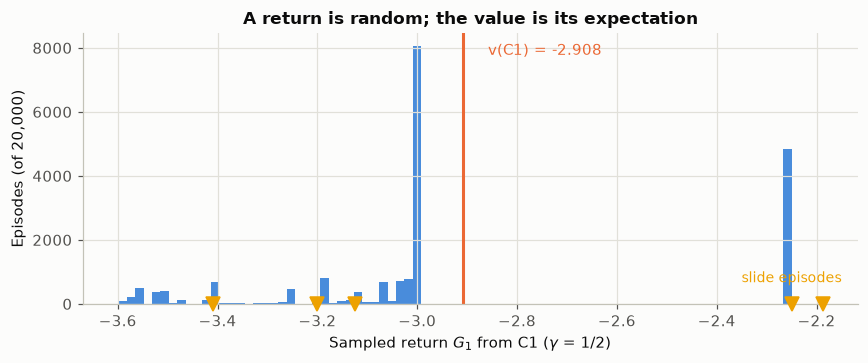

Monte Carlo mean -2.908 ± 0.003   exact v(C1) = -2.908


In [10]:
def sample_returns(start, gamma, n_episodes, rng, n_steps=400):
    """Vectorized sampling of n_episodes returns from `start` (Sleep is absorbing with reward 0)."""
    s = np.full(n_episodes, S[start])
    G = np.zeros(n_episodes)
    cum_P = np.cumsum(P, axis=1)
    cum_P[:, -1] = 1.0                                # guard against rounding (row sums 0.999...)
    for t in range(n_steps):
        G += gamma**t * R[s]
        u = rng.random(n_episodes)
        s = (u[:, None] > cum_P[s]).sum(axis=1)      # sample next state from row s of P
    return G


def solve_mrp(gamma, rewards=R, terminal=("Sleep",)):
    """v = (I - gamma P)^(-1) R on the non-terminal states, v = 0 on terminal states (see section 9)."""
    keep = [S[s] for s in STATES if s not in terminal]
    v = np.zeros(len(STATES))
    v[keep] = np.linalg.solve(np.eye(len(keep)) - gamma * P[np.ix_(keep, keep)], rewards[keep])
    return v


G_C1 = sample_returns("C1", 0.5, 20_000, rng)
v_half = solve_mrp(0.5)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(G_C1, bins=80, color=PALETTE[0], alpha=0.85)
ax.axvline(v_half[S["C1"]], color=PALETTE[1], lw=2)
ax.text(v_half[S["C1"]] + 0.05, ax.get_ylim()[1] * 0.92, f"v(C1) = {v_half[S['C1']]:.3f}", color=PALETTE[1])
for g_slide in SLIDE_RETURNS + [G_worked]:
    ax.plot(g_slide, 0, marker="v", color=PALETTE[3], ms=9, clip_on=False, zorder=5)
ax.text(-2.25, ax.get_ylim()[1] * 0.08, "slide episodes", color=PALETTE[3], ha="center", fontsize=9)
ax.set_xlabel("Sampled return $G_1$ from C1 ($\\gamma$ = 1/2)")
ax.set_ylabel("Episodes (of 20,000)")
ax.set_title("A return is random; the value is its expectation")
plt.tight_layout()
plt.show()
print(f"Monte Carlo mean {G_C1.mean():.3f} ± {G_C1.std() / np.sqrt(len(G_C1)):.3f}   exact v(C1) = {v_half[S['C1']]:.3f}")
assert abs(G_C1.mean() - v_half[S["C1"]]) < 4 * G_C1.std() / np.sqrt(len(G_C1))

## 6. 상태 가치 함수 (Example: State-Value Function for Student MRP (1)–(3))

$\gamma = 0, 0.9, 1$일 때 모든 상태의 가치 $v(s)$를 구합니다. 계산은 9절의 행렬 풀이 $v = (I-\gamma\mathcal{P})^{-1}\mathcal{R}$ 입니다.
(Sleep은 종료 상태이므로 $v(\text{Sleep}) = 0$으로 두고 나머지 6개 상태에 대해 풉니다.)

state     slide  computed       slide  computed       slide  computed   
              gamma = 0.0           gamma = 0.9           gamma = 1.0   
C1         -2.0    -2.000        -5.0    -5.013       -12.5   -12.543   
C2         -2.0    -2.000         0.9     0.943         1.5     1.457   
C3         -2.0    -2.000         4.1     4.087         4.3     4.321   
Pass       10.0    10.000        10.0    10.000        10.0    10.000   
Pub         1.0     1.000         1.9     1.908         0.8     0.802   
YT         -1.0    -1.000        -7.6    -7.638       -22.5   -22.543   
Sleep       0.0     0.000         0.0     0.000         0.0     0.000   


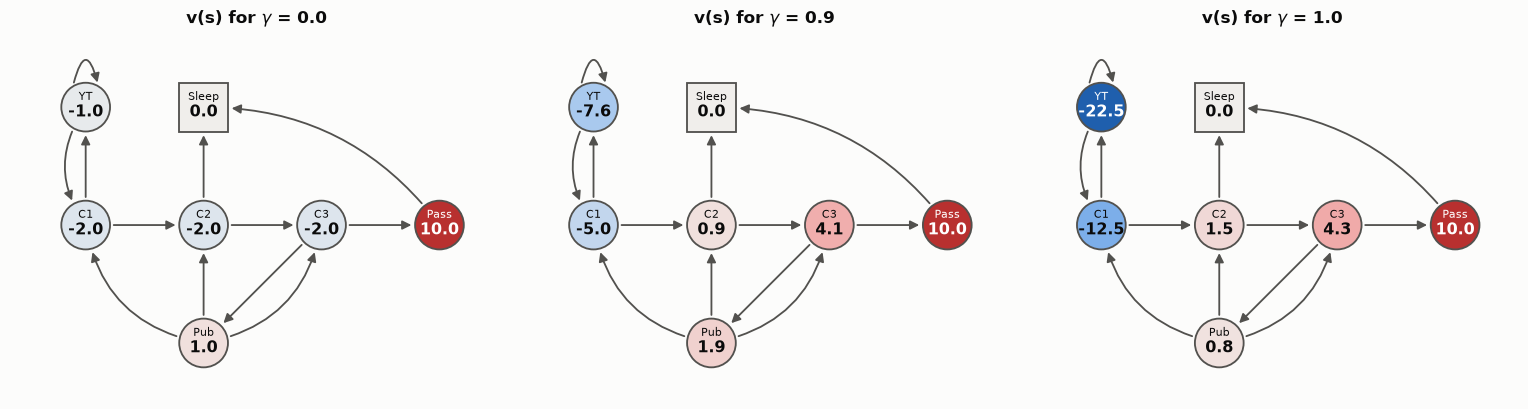

In [11]:
SLIDE_V = {  # 슬라이드 그림 값 (C1, C2, C3, Pass, Pub, YT, Sleep)
    0.0: [-2, -2, -2, 10, 1, -1, 0],
    0.9: [-5.0, 0.9, 4.1, 10, 1.9, -7.6, 0],
    1.0: [-12.5, 1.5, 4.3, 10, 0.8, -22.5, 0],
}
V = {g: solve_mrp(g) for g in SLIDE_V}

print(f"{'state':6}" + "".join(f"{'slide':>9}{'computed':>10}   " for _ in SLIDE_V))
print(f"{'':6}" + "".join(f"{'gamma = ' + str(g):>19}   " for g in SLIDE_V))
for s in STATES:
    print(f"{s:6}" + "".join(f"{SLIDE_V[g][S[s]]:9.1f}{V[g][S[s]]:10.3f}   " for g in SLIDE_V))
for g in SLIDE_V:
    assert np.all(np.abs(V[g] - np.array(SLIDE_V[g])) <= 0.05 + 1e-9)   # slide rounds to 1 decimal

norm = TwoSlopeNorm(vcenter=0, vmin=-23, vmax=10)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.1))
for ax, g in zip(axes, SLIDE_V):
    draw_chain(ax, values=V[g], norm=norm, edge_labels=False, title=f"v(s) for $\\gamma$ = {g}")
plt.tight_layout()
plt.show()

모든 값이 슬라이드와 일치합니다(소수 첫째 자리 반올림).

- $\gamma=0$: 에이전트가 바로 다음 보상만 보므로 $v(s) = \mathcal{R}_s$ 입니다.
- $\gamma$가 커질수록 먼 미래가 반영됩니다. C3는 Pass($+10$)로 이어질 가능성 덕분에 값이 커지고,
  YT는 오래 머무르며 $-1$을 계속 받기 때문에 $-1 \to -7.6 \to -22.5$로 급격히 나빠집니다.

## 7. 벨만 방정식 확인 (Example: Bellman Equation for Student MRP / Bellman Equation: Checking Every State)

$$v(s) = \mathcal{R}_s + \gamma \sum_{s'} \mathcal{P}_{ss'}\, v(s')$$

가 **모든** 상태에서 성립하는지 $\gamma=1$로 확인합니다. 먼저 정확한 값으로, 다음으로 슬라이드처럼 그림의 반올림된 값으로 계산합니다.

In [12]:
v1 = V[1.0]
rhs = R + 1.0 * P @ v1
print(f"{'state':6} {'v(s)':>9} {'R_s + sum P v':>14}")
for s in STATES:
    print(f"{s:6} {v1[S[s]]:9.4f} {rhs[S[s]]:14.4f}")
assert np.allclose(rhs, v1)                     # exact values satisfy the Bellman equation in every state

# 슬라이드의 계산 그대로 (그림 "Example: Bellman Equation for Student MRP"의 반올림 값 -13, 1.5, 4.3, 10, 0, -23, 0.8 사용)
fig_v = {"C1": -13, "C2": 1.5, "C3": 4.3, "Pass": 10, "Sleep": 0, "YT": -23, "Pub": 0.8}
slide_lines = [   # (state, slide's right-hand side, slide's result)
    ("Pass", 10 + 1.0 * fig_v["Sleep"], 10),
    ("C3", -2 + 0.6 * fig_v["Pass"] + 0.4 * fig_v["Pub"], 4.32),
    ("C2", -2 + 0.8 * fig_v["C3"] + 0.2 * fig_v["Sleep"], 1.44),
    ("Pub", 1 + 0.2 * fig_v["C1"] + 0.4 * fig_v["C2"] + 0.4 * fig_v["C3"], 0.72),
    ("C1", -2 + 0.5 * fig_v["C2"] + 0.5 * fig_v["YT"], -12.75),
]
print(f"\n{'state':6} {'slide RHS':>10} {'value in figure':>16} {'exact v':>9}")
for s, rhs_slide, result_slide in slide_lines:
    assert abs(rhs_slide - result_slide) < 1e-9          # we reproduce the slide's arithmetic
    print(f"{s:6} {rhs_slide:10.2f} {fig_v[s]:16.1f} {v1[S[s]]:9.3f}")

state       v(s)  R_s + sum P v
C1      -12.5432       -12.5432
C2        1.4568         1.4568
C3        4.3210         4.3210
Pass     10.0000        10.0000
Pub       0.8025         0.8025
YT      -22.5432       -22.5432
Sleep     0.0000         0.0000

state   slide RHS  value in figure   exact v
Pass        10.00             10.0    10.000
C3           4.32              4.3     4.321
C2           1.44              1.5     1.457
Pub          0.72              0.8     0.802
C1         -12.75            -13.0   -12.543


- 정확한 값에서는 벨만 방정식이 모든 상태에서 (부동소수점 오차 수준으로) 정확히 성립합니다.
- 슬라이드의 한 줄씩 계산은 그대로 재현됩니다($4.32, 1.44, 0.72, -12.75$). 다만 Pub과 C1 줄은 그림 속 값($0.8$, $-13$)과 조금 다릅니다.
  이는 입력으로 쓴 $v(\text{C1}) = -13$, $v(\text{YT}) = -23$이 정확한 값 $-12.54$, $-22.54$를 정수로 반올림한 값이기 때문입니다.
  슬라이드 *(3)* 의 소수 첫째 자리 값($-12.5$, $-22.5$)을 쓰면 Pub $= 0.82$, C1 $= -12.5$로 맞아떨어집니다.

In [13]:
# 소수 첫째 자리 값(슬라이드 (3))으로 다시 계산
v3 = dict(zip(STATES, SLIDE_V[1.0]))
pub_rhs = 1 + 0.2 * v3["C1"] + 0.4 * v3["C2"] + 0.4 * v3["C3"]
c1_rhs = -2 + 0.5 * v3["C2"] + 0.5 * v3["YT"]
print(f"with one-decimal values: Pub = {pub_rhs:.2f} (figure 0.8),  C1 = {c1_rhs:.2f} (figure -12.5)")

with one-decimal values: Pub = 0.82 (figure 0.8),  C1 = -12.50 (figure -12.5)


## 8. 값을 하나씩 읽어 낼 수 없는 이유 (Why the Values Cannot Be Read Off One at a Time)

YT에는 자기 자신으로 가는 화살표가 있어서 $v(\text{YT})$가 방정식 양변에 나타납니다.

$$v(\text{YT}) = -1 + 0.9\,v(\text{YT}) + 0.1\,v(\text{C1}) \;\Longrightarrow\; 0.1\,v(\text{YT}) = -1 + 0.1\,v(\text{C1}).$$

In [14]:
for v_c1, label in [(-13, "slide (rounded v(C1) = -13)"), (v1[S["C1"]], "exact v(C1)")]:
    v_yt = (-1 + 0.1 * v_c1) / 0.1
    print(f"{label:30}: v(C1) = {v_c1:8.3f}  ->  v(YT) = {v_yt:8.3f}")
assert abs((-1 + 0.1 * -13) / 0.1 - (-23)) < 1e-9
assert abs((-1 + 0.1 * v1[S["C1"]]) / 0.1 - v1[S["YT"]]) < 1e-9

stays = rng.geometric(0.1, size=100_000)          # number of steps spent in YT before leaving
print(f"average number of steps in YT: {stays.mean():.2f}  (theory 1/0.1 = 10)")

slide (rounded v(C1) = -13)   : v(C1) =  -13.000  ->  v(YT) =  -23.000
exact v(C1)                   : v(C1) =  -12.543  ->  v(YT) =  -22.543
average number of steps in YT: 10.00  (theory 1/0.1 = 10)


슬라이드의 $-23$은 반올림된 $v(\text{C1}) = -13$에서 나온 값이고, 정확한 값은 $-22.54$입니다.
YT에서는 평균 10스텝 머무르며 매번 $-1$을 받으므로 대략 $-10$에, 그 뒤 C1의 가치($\approx -12.5$)가 더해져 $\approx -22.5$가 됩니다.

그렇다면 "숫자를 대입하는 계산"을 여러 번 반복하면 어떨까요? $v_{k+1} = \mathcal{R} + \gamma\mathcal{P} v_k$ 를 $v_0 = 0$에서 시작해 반복해 봅니다.

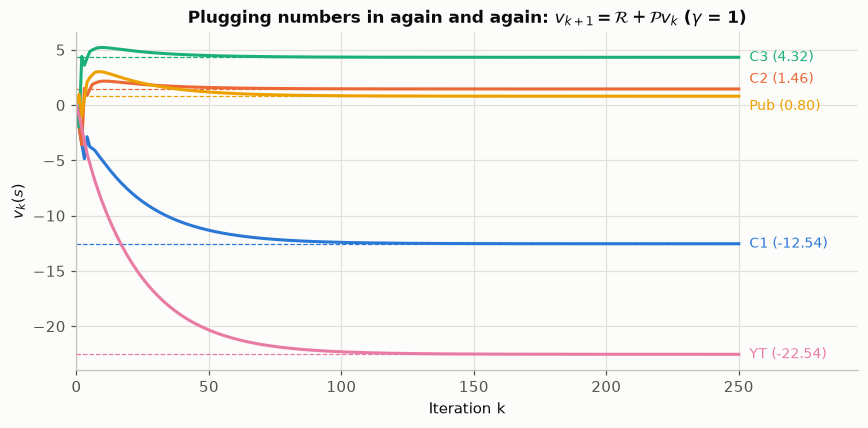

k =  10: v_k(YT) =   -8.936   (exact -22.543)
k =  50: v_k(YT) =  -20.347   (exact -22.543)
k = 100: v_k(YT) =  -22.318   (exact -22.543)
k = 250: v_k(YT) =  -22.543   (exact -22.543)


In [15]:
K = 250
history = np.zeros((K + 1, 7))
for k in range(K):
    history[k + 1] = R + 1.0 * P @ history[k]

fig, ax = plt.subplots(figsize=(8, 4))
label_nudge = {"C2": 0.9, "Pub": -0.9}           # keep the two close labels apart
for i, s in enumerate(["C1", "C2", "C3", "Pub", "YT"]):
    ax.plot(history[:, S[s]], color=PALETTE[i])
    ax.hlines(v1[S[s]], 0, K, color=PALETTE[i], lw=0.8, ls="--")
    ax.text(K + 4, v1[S[s]] + label_nudge.get(s, 0), f"{s} ({v1[S[s]]:.2f})", color=PALETTE[i], va="center", fontsize=9)
ax.set_xlim(0, K + 45)
ax.set_xlabel("Iteration k")
ax.set_ylabel("$v_k(s)$")
ax.set_title("Plugging numbers in again and again: $v_{k+1} = \\mathcal{R} + \\mathcal{P} v_k$ ($\\gamma$ = 1)")
plt.tight_layout()
plt.show()

for k in [10, 50, 100, 250]:
    print(f"k = {k:3d}: v_k(YT) = {history[k, S['YT']]:8.3f}   (exact {v1[S['YT']]:.3f})")

반복 대입도 결국 정답(점선)으로 수렴하지만, YT와 C1처럼 되먹임(self-loop, 순환)이 있는 상태는 수백 번이 걸립니다.
모든 방정식이 서로 얽혀 있으므로 한 번에 풀려면 연립방정식 전체를 풀어야 합니다 — 다음 절의 행렬 형태입니다.

## 9. 행렬 형태와 직접 풀이 (Bellman Equation in Matrix Form / Solving the Bellman Equation)

$$v = \mathcal{R} + \gamma\mathcal{P}v \;\Longrightarrow\; (I - \gamma\mathcal{P})\,v = \mathcal{R} \;\Longrightarrow\; v = (I-\gamma\mathcal{P})^{-1}\mathcal{R}$$

$n$개 상태에 대해 $O(n^3)$ 계산이므로 작은 MRP에서만 쓸 수 있습니다.

In [16]:
gamma = 0.9
A = np.eye(7) - gamma * P
print("I - 0.9 P =\n", A)
v_inv = np.linalg.inv(A) @ R               # 교과서 식 그대로
v_solve = np.linalg.solve(A, R)            # 실제로는 역행렬 대신 solve 사용 (더 빠르고 정확)
print("\nv (inverse) =", v_inv)
print("v (solve)   =", v_solve)
assert np.allclose(v_inv, v_solve) and np.allclose(v_solve, V[0.9])

# gamma = 1 에서는 Sleep의 자기 전이(확률 1) 때문에 I - P 가 특이 행렬(singular)이 됩니다
print("\nrank of (I - P) with Sleep included:", np.linalg.matrix_rank(np.eye(7) - P), "of 7")
keep = [S[s] for s in STATES if s != "Sleep"]
print("rank after removing the terminal state Sleep:", np.linalg.matrix_rank(np.eye(6) - P[np.ix_(keep, keep)]), "of 6")

I - 0.9 P =
 [[ 1.   -0.45  0.    0.    0.   -0.45  0.  ]
 [ 0.    1.   -0.72  0.    0.    0.   -0.18]
 [ 0.    0.    1.   -0.54 -0.36  0.    0.  ]
 [ 0.    0.    0.    1.    0.    0.   -0.9 ]
 [-0.18 -0.36 -0.36  0.    1.    0.    0.  ]
 [-0.09  0.    0.    0.    0.    0.19  0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.1 ]]

v (inverse) = [-5.01  0.94  4.09 10.    1.91 -7.64  0.  ]
v (solve)   = [-5.01  0.94  4.09 10.    1.91 -7.64  0.  ]

rank of (I - P) with Sleep included: 6 of 7
rank after removing the terminal state Sleep: 6 of 6


$\gamma<1$이면 7개 상태 전체로 바로 풀 수 있습니다(Sleep은 $v = 0/(1-\gamma) = 0$이 자동으로 나옵니다).
$\gamma=1$이면 Sleep 행이 $1 - 1 = 0$이 되어 $I-\mathcal{P}$가 역행렬을 갖지 않으므로, 종료 상태의 가치를 $0$으로 고정하고 나머지 상태만 풉니다.
위의 `solve_mrp`가 바로 그렇게 합니다.

## 직접 해보기

1. 6절에서 $\gamma = 0.5, 0.99$ 도 추가해 보세요. $v(\text{YT})$와 $v(\text{C1})$이 $\gamma$에 따라 어떻게 변하나요?
2. `TRANSITIONS`에서 Pub의 전이를 C1 $0.2$ → $0$, C3 $0.4$ → $0.6$으로 바꾸면 $v(\text{C3})$, $v(\text{Pub})$은 어떻게 바뀌나요?
3. 모든 상태의 보상을 $1$(Sleep만 $0$), $\gamma=1$로 두면 가치는 "종료까지 남은 평균 스텝 수"가 됩니다.
   `solve_mrp(1.0, rewards=np.array([1, 1, 1, 1, 1, 1, 0.]))`의 C1 값을 3절 히스토그램의 평균 길이와 비교해 보세요 (히스토그램은 Sleep까지 포함한 상태 수를 세므로 1 차이가 납니다).
4. 8절의 반복 대입을 $\gamma = 0.9$로 하면 몇 번 만에 수렴하나요? 수렴 속도가 $\gamma$에 따라 어떻게 달라지나요?